In [333]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
import random
import scipy


from thinkbayes import _DictWrapper
import bisect
import thinkbayes

class Pmf(_DictWrapper):

    def __add__(self, other):
        pmf = Pmf()
        for v1, p1 in self.Items():
            for v2, p2 in other.Items():
                pmf.Incr(v1+v2, p1*p2)
        return pmf

    def Normalize(self, fraction=1.0):
        if self.log:
            raise ValueError("Pmf is under a log transforms")
        total = self.Total()
        if total == 0.0:
            raise ValueError("total probability is zero")
            return total
        factor = float(fraction)/total
        for x in self.d:
            self.d[x] *=factor
        return total

    def Random(self):
        if len(self.d) == 0:
            raise ValueError('Pmf contains no values.')

        target = random.random()
        total = 0.0
        for x, p in self.d.items():
            total += p
            if total >= target:
                return x

        assert False

    def Max(self, k):
        cdf = self.MakeCdf()
        cdf.ps = [p**k for p in cdf.ps]
        return cdf

    def MakeCdf(self, name=None):
        return MakeCdfFromPmf(self, name=name)
    

class Suite(Pmf):
    def Update(self, data):
        for hypo in list(self.Values()):
            like = self.Likelihood(data, hypo)
            self.Mult(hypo, like)
        return self.Normalize()
    
    def MakeCdf(self, name=None):
            return MakeCdfFromPmf(self, name=name)

    def UpdateSet(self, dataset):
        for data in dataset:
            for hypo in self.Values():
                like = self.Likelihood(data, hypo)
                self.Mult(hypo, like)
        return self.Normalize()

def MakeCdfFromPmf(pmf, name=None):
    if name == None:
        name = pmf.name
    return MakeCdfFromItems(pmf.Items(), name)

def MakeCdfFromItems(items, name=''):
    runsum = 0
    xs = []
    cs = []

    for value, count in sorted(items):
        runsum += count
        xs.append(value)
        cs.append(runsum)

    total = float(runsum)
    ps = [c/total for c in cs]
    cdf = Cdf(xs, ps, name)
    return cdf

def MakePmfFromList(t, name=""):
    hist = MakeHistFromList(t)
    d = hist.GetDict()
    pmf = Pmf(d, name)
    pmf.Normalize()
    return pmf

def MakeHistFromList(t, name=''):
    hist = Hist(name=name)
    [hist.Incr(x) for x in t]
    return hist

def MakePmfFromCdf(cdf, name=None):
    if name is None:
        name = cdf.name

    pmf = Pmf(name=name)
    prev = 0.0
    for val, prob in cdf.Items():
        pmf.Incr(val, prob - prev)
        prev = prob
    return pmf


def SampleSum(dists, n):
    pmf = MakePmfFromList(RandomSum(dists) for i in range(n))
    return pmf

def SampleMax(dists, n):
    pmf = MakePmfFromList(RandomMax(dists) for i in range(n))
    return pmf


def RandomSum(dists):
    total = sum(dist.Random() for dist in dists)
    return total

def RandomMax(dists):
    total = max(dist.Random() for dist in dists)
    return total

def EvalPoissonPmf(k, lam):
    return scipy.stats.poisson.pmf(k, lam)

def EvalGaussianPdf(mu, sigma, x):
    return scipy.stats.norm.pdf(x, mu, sigma)

def MakePoissonPmf(lam, high, step=1):
    pmf = Pmf()
    for k in range(0, high+1, step):
        p = EvalPoissonPmf(k, lam)
        pmf.Set(k,p)
    pmf.Normalize()
    return pmf

class Cdf(object):
    def __init__(self, xs=None, ps=None, name=''):
        self.xs = [] if xs is None else xs
        self.ps = [] if ps is None else ps
        self.name = name

    def Value(self,p):
        if p < 0 or p > 1:
            raise ValueError('Probability p must be in range [0, 1]')

        if p == 0: return self.xs[0]
        if p == 1: return self.xs[-1]
        index = bisect.bisect(self.ps, p)
        if p == self.ps[index - 1]:
            return self.xs[index - 1]
        else:
            return self.xs[index]

    def Max(self, k):
        cdf = self.Copy()
        cdf.ps = [p**k for p in cdf.ps]
        return cdf

    def Items(self):
        return zip(self.xs, self.ps)
        
class Hist(_DictWrapper):

    pass


In [334]:
def MakeGaussianPmf(mu, sigma, num_sigmas, n=201):
    pmf = Pmf()
    low = mu - num_sigmas*sigma
    high = mu + num_sigmas*sigma

    for x in np.linspace(low, high, n):
        p = EvalGaussianPdf(mu,sigma,x)
        pmf.Set(x,p)

    pmf.Normalize()
    return pmf

In [335]:
USE_SUMMARY_DATA = True

class Hockey(Suite):
    def __init__(self, name=''):
        if USE_SUMMARY_DATA:
            # prior based on each team's average goals scored
            mu = 2.8
            sigma = 0.3
        else:
            # prior based on each pair-wise match-up
            mu = 2.8
            sigma = 0.85

        pmf = MakeGaussianPmf(mu, sigma, 4)
        Suite.__init__(self, pmf, name=name)

    def Likelihood(self, data, hypo):
        lam = hypo
        k = data
        like = EvalPoissonPmf(k, lam)
        return like

    
def MakeGoalPmf(suite, high=10):
    metapmf = Pmf()

    for lam, prob in suite.Items():
        mix = thinkbayes.MakeMixture(metapmf, name=suite.name)
        return mix

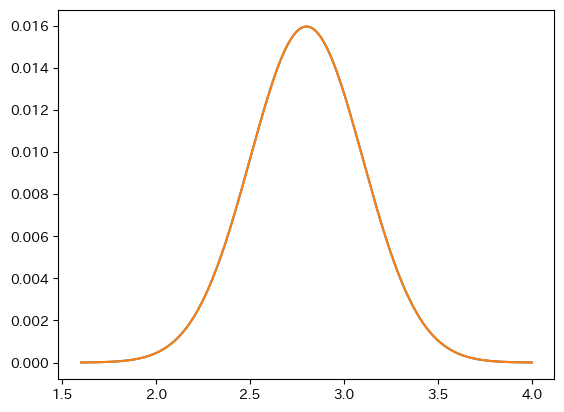

In [336]:
suite1 = Hockey('bruins')
suite2 = Hockey('canucks')

lam1, prob1 = zip(*suite1.Items())
lam2, prob2 = zip(*suite2.Items())
plt.plot(lam1, prob1, label="Bruins")
plt.plot(lam2, prob2, label="Canucks")

Bruins: 2.88
Canucks: 2.61
Bruins MLE: 2.87
Canucks MLE: 2.61


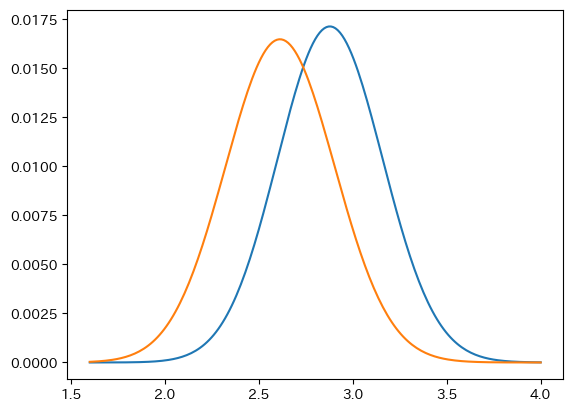

In [337]:

suite1.UpdateSet([0,2,8,4])
suite2.UpdateSet([1,3,1,0])

lam1, prob1 = zip(*suite1.Items())
lam2, prob2 = zip(*suite2.Items())
plt.plot(lam1, prob1, label="Bruins")
plt.plot(lam2, prob2, label="Canucks")


mean1 = sum(l * p for l, p in zip(lam1, prob1))
mean2 = sum(l * p for l, p in zip(lam2, prob2))

mle1 = max(suite1.Items(), key=lambda item: item[1])[0]
mle2 = max(suite2.Items(), key=lambda item: item[1])[0]

print(f"Bruins: {mean1:.2f}")
print(f"Canucks: {mean2:.2f}")
print(f"Bruins MLE: {mle1:.2f}")
print(f"Canucks MLE: {mle2:.2f}")

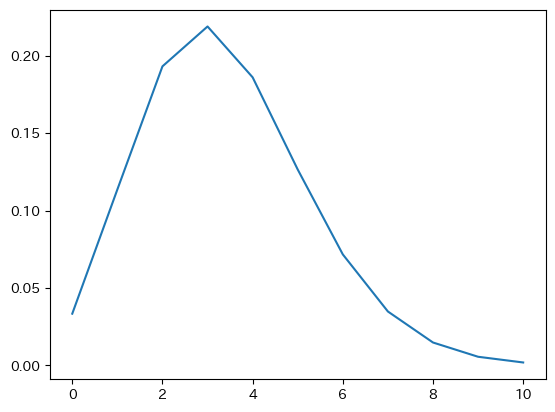

In [340]:
lam = 3.4
goal_dist = MakePoissonPmf(lam, 10)

goal_dist.Items()

lam1, prob1 = zip(*goal_dist.Items())

plt.plot(lam1, prob1, label="")

In [ ]:
df = pd.read_csv("hockey_data.csv")

df.head()

,Season,Game,Team,Pd1,Pd2,Pd3,OT,SO Win,Total
0,2009,20001,NYR,0,1,1,0,0,2
1,2009,20001,TBL,0,0,1,0,0,1
2,2009,20002,OTT,1,2,0,0,0,3
3,2009,20002,PIT,1,1,1,1,0,4
4,2009,20003,NYR,0,2,0,0,0,2


In [ ]:
df = df[df["Season"] == 2011]

team_lams = df.groupby("Team")["Total"].mean()
print(team_lams[:10])

lams = team_lams.values
mu = np.mean(lams)
mu0 = mu.copy()
sigma = np.std(lams)
sigma0 = sigma.copy()

print(f"mu: {mu:.2f}")
print(f"sigma: {sigma:.2f}")

Team
ANA    2.914634
ATL    2.658537
BOS    3.000000
BUF    2.987805
CAR    2.878049
CBJ    2.621951
CGY    3.048780
CHI    3.146341
COL    2.768293
DAL    2.768293
Name: Total, dtype: float64
mu: 2.79
sigma: 0.26


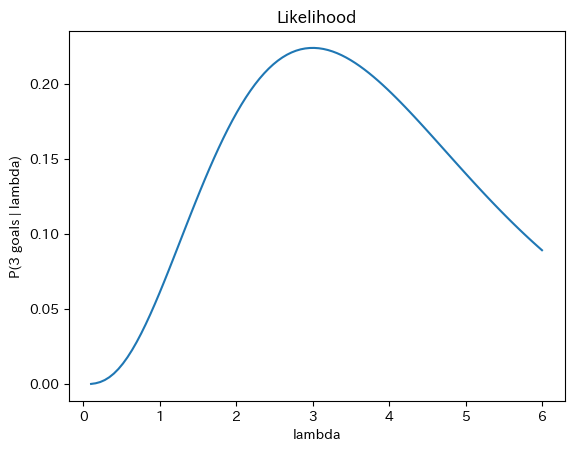

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial


# 観測した得点
k = 3

# λの候補
lambdas = np.linspace(0.1, 6, 100)


# ポワソン確率
def poisson_pmf(k, lam):
    return np.exp(-lam) * lam**k / factorial(k)


# λごとに「3点が起こる確率」を計算
likelihood = []

for lam in lambdas:
    p = poisson_pmf(k, lam)
    likelihood.append(p)


# グラフ
plt.plot(lambdas, likelihood)

plt.xlabel("lambda")
plt.ylabel("P(3 goals | lambda)")
plt.title("Likelihood")

plt.show()

過去データ
チーム数     = 30
平均         = 2.788
標準偏差     = 0.258

Gamma分布
shape (alpha) = 116.791
rate  (beta)  = 41.893
scale          = 0.02387


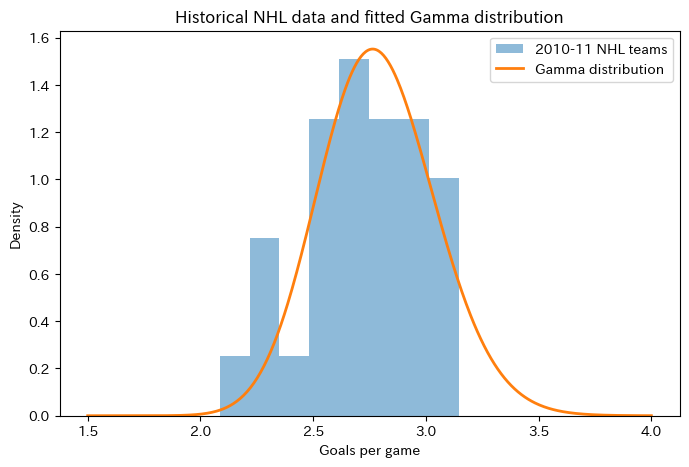

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma


# --------------------------------------------------
# 1. 2010-11 NHL 各チームの Goals per Game (G/GP)
# --------------------------------------------------

goals_per_game = np.array([
    3.134,  # Detroit
    3.146,  # Vancouver
    3.073,  # Chicago
    3.122,  # Philadelphia
    2.963,  # San Jose
    2.939,  # Calgary
    2.939,  # Tampa Bay
    2.976,  # Boston
    2.927,  # Buffalo
    2.866,  # Anaheim
    2.878,  # St. Louis
    2.817,  # Carolina
    2.780,  # Pittsburgh
    2.756,  # Phoenix
    2.732,  # NY Rangers
    2.744,  # NY Islanders
    2.695,  # Colorado
    2.707,  # Dallas
    2.671,  # Washington
    2.561,  # Columbus
    2.598,  # Nashville
    2.549,  # Los Angeles
    2.598,  # Montreal
    2.659,  # Atlanta
    2.598,  # Toronto
    2.476,  # Minnesota
    2.329,  # Edmonton
    2.329,  # Florida
    2.317,  # Ottawa
    2.085,  # New Jersey
])


# --------------------------------------------------
# 2. 過去データから平均と標準偏差を計算
# --------------------------------------------------

mu = goals_per_game.mean()
mu = mu0
sigma = goals_per_game.std(ddof=0)
sigma

print("過去データ")
print(f"チーム数     = {len(goals_per_game)}")
print(f"平均         = {mu:.3f}")
print(f"標準偏差     = {sigma:.3f}")


# --------------------------------------------------
# 3. 平均と標準偏差から Gamma のパラメータを計算
# --------------------------------------------------

alpha = (mu / sigma) ** 2
beta = mu / sigma**2
scale = 1 / beta

print()
print("Gamma分布")
print(f"shape (alpha) = {alpha:.3f}")
print(f"rate  (beta)  = {beta:.3f}")
print(f"scale          = {scale:.5f}")


# --------------------------------------------------
# 4. 作った Gamma 分布の密度を計算
# --------------------------------------------------

xs = np.linspace(1.5, 4.0, 500)

ys = gamma.pdf(
    xs,
    a=alpha,
    scale=scale
)


# --------------------------------------------------
# 5. 過去データと Gamma 分布をグラフで比較
# --------------------------------------------------

plt.figure(figsize=(8, 5))

# 過去30チームのデータ
plt.hist(
    goals_per_game,
    bins=8,
    density=True,
    alpha=0.5,
    label="2010-11 NHL teams"
)

# 作った Gamma 分布
plt.plot(
    xs,
    ys,
    linewidth=2,
    label="Gamma distribution"
)

plt.xlabel("Goals per game")
plt.ylabel("Density")
plt.title("Historical NHL data and fitted Gamma distribution")
plt.legend()

plt.show()

事前分布
alpha = 110.707
beta  = 39.711
mean  = 2.788
std   = 0.265

観測データ
得点 = [1 3 1 0]
合計得点 = 5
試合数 = 4
平均得点 = 1.25

事後分布:Bruins
alpha = 115.707
beta  = 43.711
事後平均 = 2.647

観測データ
得点 = [0 2 8 4]
合計得点 = 14
試合数 = 4
平均得点 = 3.5

事後分布:Sharks
alpha = 124.707
beta  = 43.711
事後平均 = 2.853


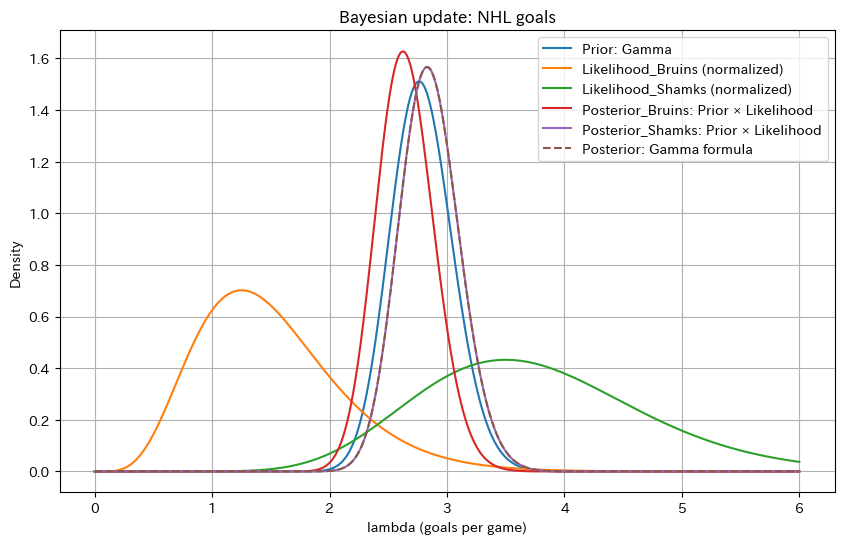

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma, poisson

# ========================================
# 1. NHLデータから得られた平均・標準偏差
# ========================================

mu = mu0
sigma = sigma0

# Gamma(alpha, beta)
# beta は rate parameter
alpha_prior = (mu / sigma) ** 2
beta_prior = mu / sigma**2

print("事前分布")
print(f"alpha = {alpha_prior:.3f}")
print(f"beta  = {beta_prior:.3f}")
print(f"mean  = {alpha_prior / beta_prior:.3f}")
print(f"std   = {np.sqrt(alpha_prior) / beta_prior:.3f}")


# ========================================
# 2. 事前分布
# ========================================

lambdas = np.linspace(0, 6, 1000)

# scipyのgammaは scale を使う
# rate beta の場合 scale = 1 / beta
prior = gamma.pdf(
    lambdas,
    a=alpha_prior,
    scale=1 / beta_prior
)


# ========================================
# 3. Bruinsの観測データ
# ========================================

data1 = np.array([1, 3, 1, 0])
data2 = np.array([0,2,8,4])

team = ["Bruins", "Sharks"]

l = {}
p = {}

for i, data in enumerate([data1, data2]):

    total_goals = data.sum()
    n_games = len(data)

    print()
    print("観測データ")
    print("得点 =", data)
    print("合計得点 =", total_goals)
    print("試合数 =", n_games)
    print("平均得点 =", total_goals / n_games)


    # ========================================
    # 4. 尤度を計算
    # ========================================

    # 各lambdaについて、
    # 「0, 2, 8, 4 というデータが出る確率」
    # を計算する
    likelihood = np.ones(len(lambdas))
    for goals in data:
        likelihood *= poisson.pmf(goals, lambdas)
        l[i] = likelihood
    # ========================================
    # 5. Bayesの公式
    #
    #     posterior ∝ prior × likelihood
    # ========================================

    unnormalized_posterior = prior * likelihood

    # 確率の合計が1になるように正規化
    posterior = (
        unnormalized_posterior
        / np.trapz(unnormalized_posterior, lambdas)
    )
    p[i] = posterior


    # ========================================
    # 6. Gamma-Poissonの公式から
    #    直接求めた事後分布
    # ========================================

    alpha_posterior = alpha_prior + total_goals
    beta_posterior = beta_prior + n_games

    posterior_gamma = gamma.pdf(
        lambdas,
        a=alpha_posterior,
        scale=1 / beta_posterior
    )
    
    print()
    print(f"事後分布:{team[i]}")
    print(f"alpha = {alpha_posterior:.3f}")
    print(f"beta  = {beta_posterior:.3f}")

    posterior_mean = alpha_posterior / beta_posterior

    print(f"事後平均 = {posterior_mean:.3f}")

# ========================================
# 7. グラフ
# ========================================

plt.figure(figsize=(10, 6))

plt.plot(
    lambdas,
    prior,
    label="Prior: Gamma"
)
likelihood = l[0]
plt.plot(
    lambdas,
    likelihood / np.trapz(likelihood, lambdas),
    label="Likelihood_Bruins (normalized)"
)

likelihood = l[1]
plt.plot(
    lambdas,
    likelihood / np.trapz(likelihood, lambdas),
    label="Likelihood_Shamks (normalized)"
)

posterior = p[0]
plt.plot(
    lambdas,
    posterior,
    label="Posterior_Bruins: Prior × Likelihood"
)

posterior = p[1]
plt.plot(
    lambdas,
    posterior,
    label="Posterior_Shamks: Prior × Likelihood"
)

plt.plot(
    lambdas,
    posterior_gamma,
    "--",
    label="Posterior: Gamma formula"
)

plt.xlabel("lambda (goals per game)")
plt.ylabel("Density")
plt.title("Bayesian update: NHL goals")
plt.legend()
plt.grid()

plt.show()

In [ ]:
def MakeGaussianPmf(mu, sigma, num_sigmas, n=101):
    pmf = Pmf()
    low = mu - num_sigmas*sigma
    higy = mu + num_sigmas*sigma

    for x in np.linspace(low, higy, n):
        p = scipy.stats.norm.pdf(mu, sigma, x)
        pmf.Set(x, p)
    pmf.Normalize()
    return pmf

In [ ]:
from scipy.stats import gamma

alpha = 2.8
qs = np.linspace(0, 15, 101)
ps = gamma.pdf(qs, alpha)

prior_hockey = Pmf(ps, qs)
prior_hockey.Normalize()

1.0

=== 元データ ===

チーム数       : 30
平均           : 2.790650
標準偏差       : 0.264479

=== Gamma分布の最尤推定 ===
alpha (shape) : 106.397228
beta  (rate)  : 38.126319
scale          : 0.026229

=== フィットしたGamma分布 ===
平均           : 2.790650
標準偏差       : 0.270545


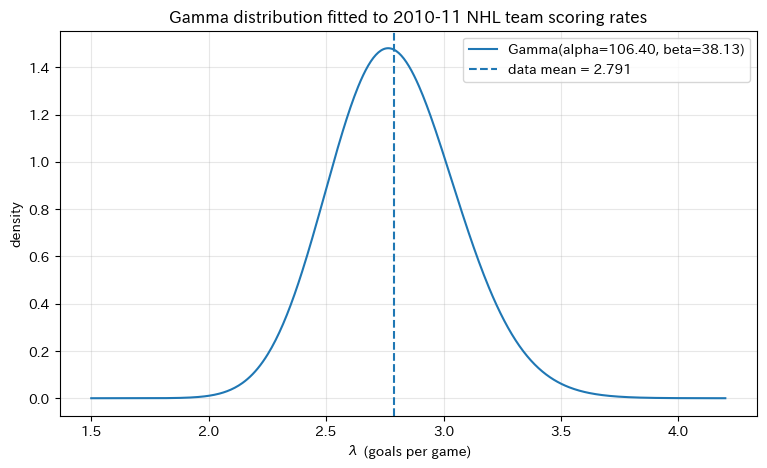

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma


# ============================================================
# 1. 2010-11 NHL
#    各チームの1試合平均得点
# ============================================================

teams = [
    "ANA", "ATL", "BOS", "BUF", "CAR",
    "CBJ", "CGY", "CHI", "COL", "DAL",
    "DET", "EDM", "FLA", "LAK", "MIN",
    "MTL", "NJD", "NSH", "NYI", "NYR",
    "OTT", "PHI", "PHX", "PIT", "SJS",
    "STL", "TBL", "TOR", "VAN", "WSH"
]

rates = np.array([
    2.914634,  # ANA
    2.658537,  # ATL
    3.000000,  # BOS
    2.987805,  # BUF
    2.878049,  # CAR
    2.621951,  # CBJ
    3.048780,  # CGY
    3.146341,  # CHI
    2.768293,  # COL
    2.768293,  # DAL
    3.182927,  # DET
    2.353659,  # EDM
    2.378049,  # FLA
    2.670732,  # LAK
    2.512195,  # MIN
    2.634146,  # MTL
    2.121951,  # NJD
    2.670732,  # NSH
    2.792683,  # NYI
    2.841463,  # NYR
    2.341463,  # OTT
    3.158537,  # PHI
    2.817073,  # PHX
    2.902439,  # PIT
    3.024390,  # SJS
    2.926829,  # STL
    3.012195,  # TBL
    2.658537,  # TOR
    3.195122,  # VAN
    2.731707   # WSH
])


# ============================================================
# 2. 元データを確認
# ============================================================

print("=== 元データ ===")

for team, rate in zip(teams, rates):
    pass
    #print(f"{team:3s}  {rate:.6f}")

print()
print(f"チーム数       : {len(rates)}")
print(f"平均           : {rates.mean():.6f}")
print(f"標準偏差       : {rates.std(ddof=0):.6f}")


# ============================================================
# 3. Gamma分布を最尤推定
#
# scipy.stats.gamma.fit()
#
# 戻り値：
#     shape, loc, scale
#
# 今回は λ >= 0 なので loc = 0 に固定
# ============================================================

alpha, loc, scale = gamma.fit(
    rates,
    floc=0
)

# ThinkBayesで使いやすい
# Gamma(alpha, beta) の beta = 1 / scale
beta = 1 / scale


print()
print("=== Gamma分布の最尤推定 ===")
print(f"alpha (shape) : {alpha:.6f}")
print(f"beta  (rate)  : {beta:.6f}")
print(f"scale          : {scale:.6f}")


# ============================================================
# 4. Gamma分布の平均・標準偏差
# ============================================================

gamma_mean = alpha / beta
gamma_std = np.sqrt(alpha) / beta

print()
print("=== フィットしたGamma分布 ===")
print(f"平均           : {gamma_mean:.6f}")
print(f"標準偏差       : {gamma_std:.6f}")


# ============================================================
# 5. Gamma分布をグラフにする
# ============================================================

x = np.linspace(1.5, 4.2, 500)

y = gamma.pdf(
    x,
    a=alpha,
    loc=0,
    scale=scale
)


plt.figure(figsize=(9, 5))

plt.plot(
    x,
    y,
    label=f"Gamma(alpha={alpha:.2f}, beta={beta:.2f})"
)

# 元データ30チームの平均
plt.axvline(
    rates.mean(),
    linestyle="--",
    label=f"data mean = {rates.mean():.3f}"
)

plt.xlabel("λ (goals per game)")
plt.ylabel("density")
plt.title("Gamma distribution fitted to 2010-11 NHL team scoring rates")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

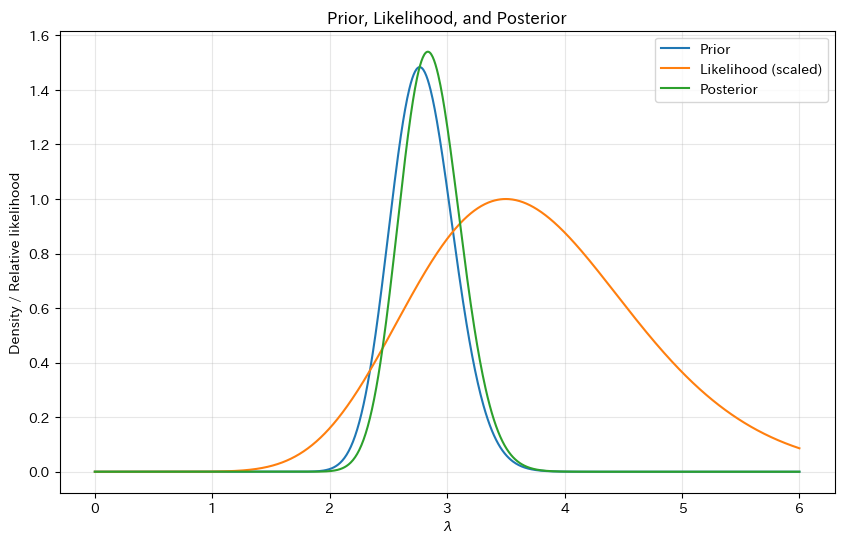

観測データ: [0, 2, 8, 4]
試合数: 4
総得点: 14

Prior
  alpha = 107.0289
  beta  = 38.3248
  mean  = 2.792679935707427

Posterior
  alpha = 121.0289
  beta  = 42.3248
  mean  = 2.8595268022530522


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma, poisson

# ============================================================
# 1. Prior
# ============================================================

alpha_prior = 107.0289
beta_prior = 38.3248

lam = np.linspace(0, 6, 1000)

prior_pdf = gamma.pdf(
    lam,
    a=alpha_prior,
    scale=1 / beta_prior
)


# ============================================================
# 2. 観測データ
# ============================================================

scores = [0, 2, 8, 4]

n_games = len(scores)
total_score = sum(scores)


# ============================================================
# 3. Likelihood
#
# P(data | λ)
# = P(0|λ) × P(2|λ) × P(8|λ) × P(4|λ)
# ============================================================

likelihood = np.ones_like(lam)

for score in scores:
    likelihood *= poisson.pmf(score, lam)

# グラフ比較用に最大値を1にする
likelihood_scaled = likelihood / likelihood.max()


# ============================================================
# 4. Posterior
# ============================================================

alpha_posterior = alpha_prior + total_score
beta_posterior = beta_prior + n_games

posterior_pdf = gamma.pdf(
    lam,
    a=alpha_posterior,
    scale=1 / beta_posterior
)


# ============================================================
# 5. グラフ
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    lam,
    prior_pdf,
    label="Prior"
)

plt.plot(
    lam,
    likelihood_scaled,
    label="Likelihood (scaled)"
)

plt.plot(
    lam,
    posterior_pdf,
    label="Posterior"
)

plt.xlabel("λ")
plt.ylabel("Density / Relative likelihood")
plt.title("Prior, Likelihood, and Posterior")

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()


# ============================================================
# 6. 数値確認
# ============================================================

print("観測データ:", scores)
print("試合数:", n_games)
print("総得点:", total_score)

print()
print("Prior")
print("  alpha =", alpha_prior)
print("  beta  =", beta_prior)
print("  mean  =", alpha_prior / beta_prior)

print()
print("Posterior")
print("  alpha =", alpha_posterior)
print("  beta  =", beta_posterior)
print("  mean  =", alpha_posterior / beta_posterior)